# Experiment: Predicting Anxiety (GAD-7) from Social Media Habits

**Research question:** Can daily screen time, sleep, late-night use, and content-related habits (passive vs. active use, dominant content type, social-comparison triggers) predict a university-age user's GAD-7 anxiety score? Do the content-related variables add predictive value beyond screen time and sleep alone?

**Plan (from `methodology.md`):** load and inspect the data, explore it, clean it, engineer features, train a mean baseline, Linear Regression and Random Forest, evaluate with RMSE / MAE / R², and finish with findings.

**Note on causality:** the data is self-reported and cross-sectional, so all results describe association and prediction, not cause and effect.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Load the data

In [2]:
df = pd.read_csv("data/social_media_mental_health.csv")
print("Shape:", df.shape)
df.head()

Shape: (8000, 15)


,User_ID,Age,Gender,User_Archetype,Primary_Platform,Daily_Screen_Time_Hours,Dominant_Content_Type,Activity_Type,Late_Night_Usage,Social_Comparison_Trigger,Sleep_Duration_Hours,GAD_7_Score,GAD_7_Severity,PHQ_9_Score,PHQ_9_Severity
0,U-b23639d2,18,Male,Hyper-Connected,Twitter/X,8.50,Gaming,Active,0,0,3.9,9,Mild,5,Mild
1,U-e7778765,20,Male,Digital Minimalist,TikTok,0.50,Gaming,Active,0,0,5.5,0,Minimal,8,Mild
2,U-76749892,18,Female,Digital Minimalist,Snapchat,0.91,Gaming,Active,0,0,8.9,1,Minimal,3,None-Minimal
3,U-dcbbd7f9,18,Female,Hyper-Connected,Snapchat,7.43,Gaming,Active,1,0,6.2,13,Moderate,0,None-Minimal
4,U-9e1ba278,18,Male,Hyper-Connected,LinkedIn,4.94,Entertainment/Comedy,Active,1,0,5.3,13,Moderate,10,Moderate


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   User_ID                    8000 non-null   str    
 1   Age                        8000 non-null   int64  
 2   Gender                     8000 non-null   str    
 3   User_Archetype             8000 non-null   str    
 4   Primary_Platform           8000 non-null   str    
 5   Daily_Screen_Time_Hours    8000 non-null   float64
 6   Dominant_Content_Type      8000 non-null   str    
 7   Activity_Type              8000 non-null   str    
 8   Late_Night_Usage           8000 non-null   int64  
 9   Social_Comparison_Trigger  8000 non-null   int64  
 10  Sleep_Duration_Hours       8000 non-null   float64
 11  GAD_7_Score                8000 non-null   int64  
 12  GAD_7_Severity             8000 non-null   str    
 13  PHQ_9_Score                8000 non-null   int64  
 14  PHQ

## 2. Exploratory data analysis

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,8000.0,19.06,1.12,18.0,18.00,19.00,20.00,22.00
Daily_Screen_Time_Hours,8000.0,4.28,2.31,0.5,2.42,4.27,6.05,11.31
Late_Night_Usage,8000.0,0.38,0.49,0.0,0.00,0.00,1.00,1.00
Social_Comparison_Trigger,8000.0,0.10,0.30,0.0,0.00,0.00,0.00,1.00
Sleep_Duration_Hours,8000.0,5.80,1.34,3.0,4.80,5.80,6.80,11.60
GAD_7_Score,8000.0,7.35,4.63,0.0,4.00,7.00,11.00,21.00
PHQ_9_Score,8000.0,5.38,4.82,0.0,1.00,5.00,9.00,23.00


### 2.1 The target: GAD-7 score

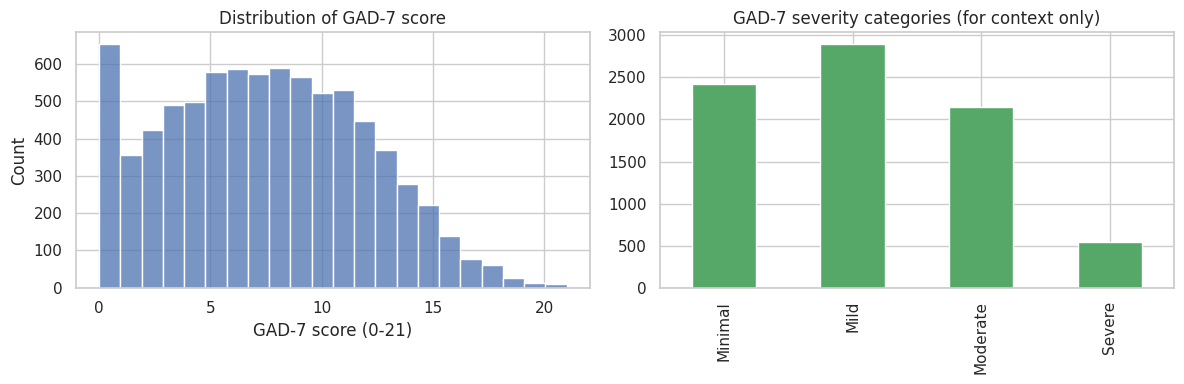

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["GAD_7_Score"], bins=22, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of GAD-7 score")
axes[0].set_xlabel("GAD-7 score (0-21)")

order = ["Minimal", "Mild", "Moderate", "Severe"]
df["GAD_7_Severity"].value_counts().reindex(order).plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title("GAD-7 severity categories (for context only)")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

### 2.2 Numeric relationships

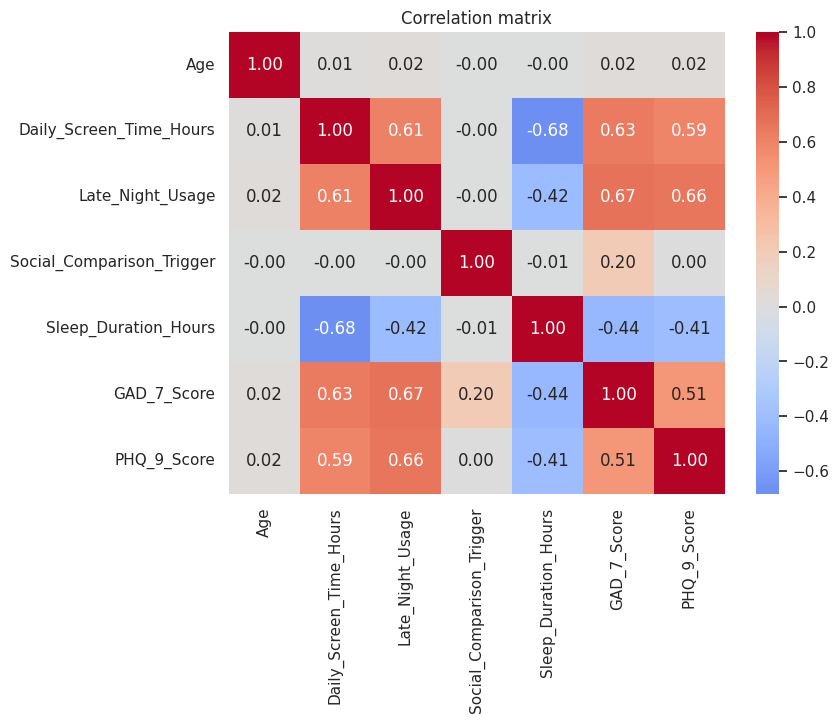

In [6]:
num_cols = ["Age", "Daily_Screen_Time_Hours", "Late_Night_Usage", "Social_Comparison_Trigger",
            "Sleep_Duration_Hours", "GAD_7_Score", "PHQ_9_Score"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

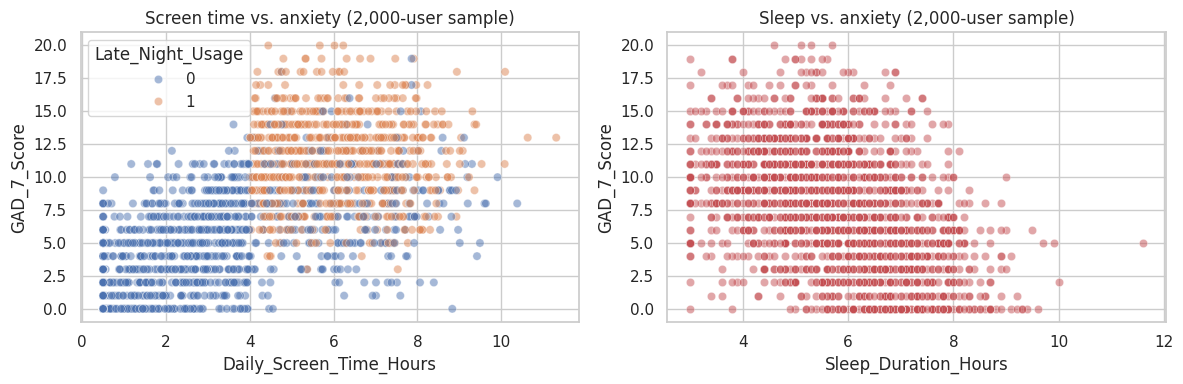

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df.sample(2000, random_state=RANDOM_STATE), x="Daily_Screen_Time_Hours",
                y="GAD_7_Score", hue="Late_Night_Usage", alpha=0.5, ax=axes[0])
axes[0].set_title("Screen time vs. anxiety (2,000-user sample)")
sns.scatterplot(data=df.sample(2000, random_state=RANDOM_STATE), x="Sleep_Duration_Hours",
                y="GAD_7_Score", alpha=0.5, ax=axes[1], color="#C44E52")
axes[1].set_title("Sleep vs. anxiety (2,000-user sample)")
plt.tight_layout()
plt.show()

### 2.3 Categorical groups

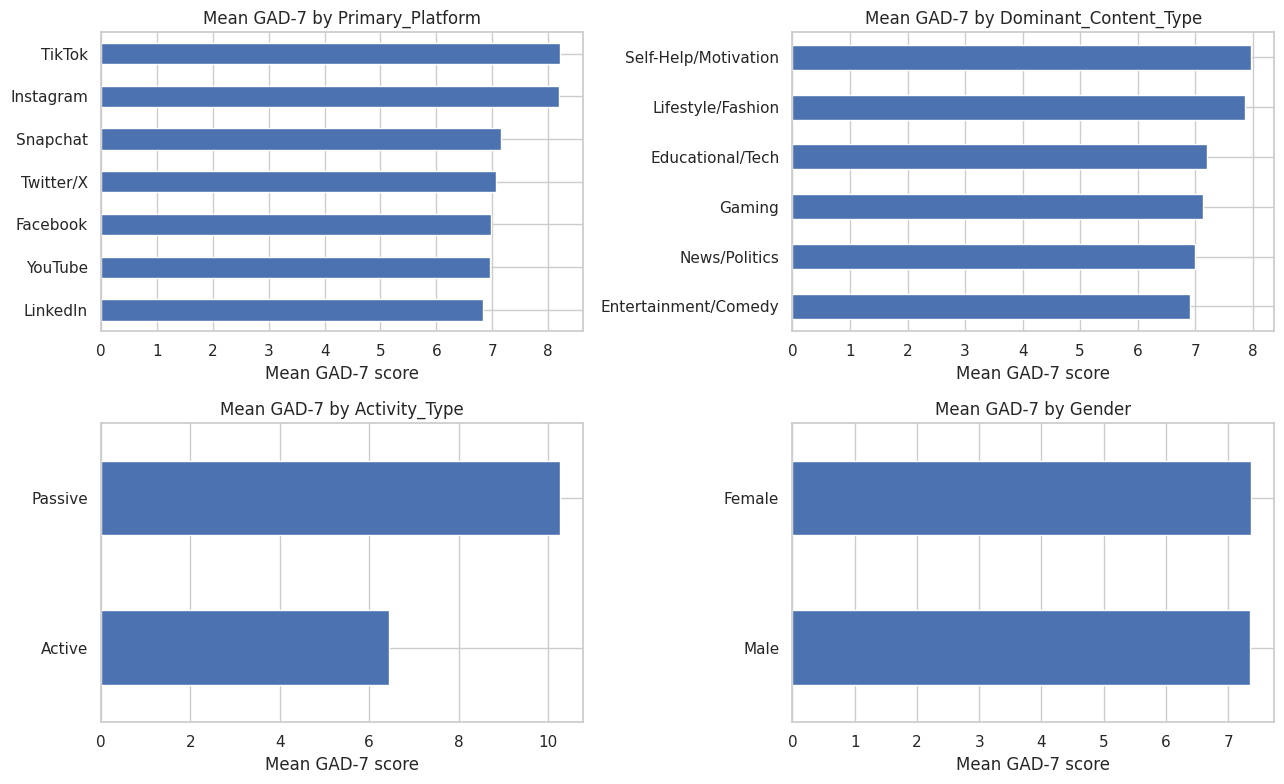

In [8]:
cat_vars = ["Primary_Platform", "Dominant_Content_Type", "Activity_Type", "Gender"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), cat_vars):
    means = df.groupby(col)["GAD_7_Score"].mean().sort_values()
    means.plot.barh(ax=ax, color="#4C72B0")
    ax.set_title(f"Mean GAD-7 by {col}")
    ax.set_xlabel("Mean GAD-7 score")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**What the EDA shows**

- Anxiety rises with screen time and late-night use and falls with sleep. These are the strongest relationships (correlations of about 0.63, 0.67 and -0.44 with GAD-7).
- Screen time and sleep are strongly negatively correlated with each other (about -0.68), so the linear model will have some multicollinearity to deal with.
- `Social_Comparison_Trigger` has almost no correlation with screen time but a clear link to anxiety (about 0.20), which makes it a candidate for a content-related signal beyond time spent.
- Passive users score noticeably higher than active users, and Instagram, TikTok, Lifestyle/Fashion and Self-Help/Motivation groups have higher average anxiety than the rest. Gender and age make almost no difference.

## 3. Data cleaning

Following the cleaning plan in `methodology.md`: missing values, duplicates, valid ranges, category consistency, outliers, then removal of leakage and redundant columns.

In [9]:
df_clean = df.copy()

print("Missing values per column:")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0] if df_clean.isna().any().any() else "None - no missing values")
print("\nDuplicate rows:", df_clean.duplicated().sum())
print("Duplicate User_IDs:", df_clean["User_ID"].duplicated().sum())

Missing values per column:
None - no missing values

Duplicate rows: 0
Duplicate User_IDs: 0


In [10]:
# Range and logic checks
checks = {
    "Age between 16 and 100": df_clean["Age"].between(16, 100).all(),
    "Screen time between 0 and 24 h": df_clean["Daily_Screen_Time_Hours"].between(0, 24).all(),
    "Sleep between 0 and 24 h": df_clean["Sleep_Duration_Hours"].between(0, 24).all(),
    "Screen time + sleep <= 24 h": ((df_clean["Daily_Screen_Time_Hours"] + df_clean["Sleep_Duration_Hours"]) <= 24).all(),
    "GAD-7 between 0 and 21": df_clean["GAD_7_Score"].between(0, 21).all(),
    "Late_Night_Usage only 0/1": set(df_clean["Late_Night_Usage"].unique()) <= {0, 1},
    "Social_Comparison_Trigger only 0/1": set(df_clean["Social_Comparison_Trigger"].unique()) <= {0, 1},
}
pd.Series(checks, name="passes").to_frame()

,passes
Age between 16 and 100,True
Screen time between 0 and 24 h,True
Sleep between 0 and 24 h,True
Screen time + sleep <= 24 h,True
GAD-7 between 0 and 21,True
Late_Night_Usage only 0/1,True
Social_Comparison_Trigger only 0/1,True


In [11]:
# Category consistency: strip whitespace and look for near-duplicate labels
for col in ["Gender", "Primary_Platform", "Dominant_Content_Type", "Activity_Type"]:
    df_clean[col] = df_clean[col].str.strip()
    print(col, "->", sorted(df_clean[col].unique()))

Gender -> ['Female', 'Male']
Primary_Platform -> ['Facebook', 'Instagram', 'LinkedIn', 'Snapchat', 'TikTok', 'Twitter/X', 'YouTube']
Dominant_Content_Type -> ['Educational/Tech', 'Entertainment/Comedy', 'Gaming', 'Lifestyle/Fashion', 'News/Politics', 'Self-Help/Motivation']
Activity_Type -> ['Active', 'Passive']


In [12]:
# Outliers: IQR rule on the two continuous predictors
rows = []
for col in ["Daily_Screen_Time_Hours", "Sleep_Duration_Hours"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    rows.append({"column": col, "lower fence": round(low, 2), "upper fence": round(high, 2),
                 "n outliers": n_out, "min": df_clean[col].min(), "max": df_clean[col].max()})
pd.DataFrame(rows)

,column,lower fence,upper fence,n outliers,min,max
0,Daily_Screen_Time_Hours,-3.03,11.5,0,0.5,11.31
1,Sleep_Duration_Hours,1.80,9.8,9,3.0,11.60


No screen-time values fall outside the IQR fences, and the nine sleep "outliers" are long sleepers (about 10 to 11.6 hours), which is plausible for young adults. I **keep** them, because only impossible values would have been removed and there are none.

### Leakage and redundancy check

Before dropping columns I confirm the reasons given in the methodology.

In [13]:
# 1) Severity labels are derived directly from the target score -> leakage
print(df_clean.groupby("GAD_7_Severity")["GAD_7_Score"].agg(["min", "max", "count"]).loc[["Minimal", "Mild", "Moderate", "Severe"]])

# 2) User_Archetype 'Passive Scroller' is identical to Activity_Type == Passive -> redundant
print()
print(pd.crosstab(df_clean["User_Archetype"], df_clean["Activity_Type"]))

                min  max  count
GAD_7_Severity                 
Minimal           0    4   2419
Mild              5    9   2891
Moderate         10   14   2145
Severe           15   21    545

Activity_Type       Active  Passive
User_Archetype                     
Average User          1993        0
Digital Minimalist    2030        0
Hyper-Connected       2068        0
Passive Scroller         0     1909


In [14]:
drop_cols = ["User_ID", "GAD_7_Severity", "PHQ_9_Score", "PHQ_9_Severity", "User_Archetype"]
df_clean = df_clean.drop(columns=drop_cols)
print("Dropped:", drop_cols)
print("Clean shape:", df_clean.shape)
df_clean.head()

Dropped: ['User_ID', 'GAD_7_Severity', 'PHQ_9_Score', 'PHQ_9_Severity', 'User_Archetype']
Clean shape: (8000, 10)


,Age,Gender,Primary_Platform,Daily_Screen_Time_Hours,Dominant_Content_Type,Activity_Type,Late_Night_Usage,Social_Comparison_Trigger,Sleep_Duration_Hours,GAD_7_Score
0,18,Male,Twitter/X,8.50,Gaming,Active,0,0,3.9,9
1,20,Male,TikTok,0.50,Gaming,Active,0,0,5.5,0
2,18,Female,Snapchat,0.91,Gaming,Active,0,0,8.9,1
3,18,Female,Snapchat,7.43,Gaming,Active,1,0,6.2,13
4,18,Male,LinkedIn,4.94,Entertainment/Comedy,Active,1,0,5.3,13


## 4. Feature engineering

New features (thresholds fixed in advance in `methodology.md`, not tuned on this data):

- `Screen_Sleep_Ratio`: hours online per hour of sleep
- `Heavy_User`: screen time of at least 6 hours per day
- `Short_Sleep`: under 6 hours of sleep
- `LateNight_x_Screen`: late-night use multiplied by screen time

These are row-wise calculations, so they cannot leak information between train and test rows. Scaling and encoding are done inside a pipeline fitted on the training set only.

In [15]:
df_fe = df_clean.copy()
df_fe["Screen_Sleep_Ratio"] = df_fe["Daily_Screen_Time_Hours"] / df_fe["Sleep_Duration_Hours"]
df_fe["Heavy_User"] = (df_fe["Daily_Screen_Time_Hours"] >= 6).astype(int)
df_fe["Short_Sleep"] = (df_fe["Sleep_Duration_Hours"] < 6).astype(int)
df_fe["LateNight_x_Screen"] = df_fe["Late_Night_Usage"] * df_fe["Daily_Screen_Time_Hours"]

print(df_fe[["Screen_Sleep_Ratio", "Heavy_User", "Short_Sleep", "LateNight_x_Screen"]].describe().round(2))
print("\nHeavy users:", df_fe["Heavy_User"].mean().round(3), "| Short sleepers:", df_fe["Short_Sleep"].mean().round(3))

       Screen_Sleep_Ratio  Heavy_User  Short_Sleep  LateNight_x_Screen
count             8000.00     8000.00      8000.00             8000.00
mean                 0.85        0.26         0.54                2.30
std                  0.62        0.44         0.50                3.07
min                  0.04        0.00         0.00                0.00
25%                  0.37        0.00         0.00                0.00
50%                  0.74        0.00         1.00                0.00
75%                  1.21        1.00         1.00                5.25
max                  3.43        1.00         1.00               11.31

Heavy users: 0.258 | Short sleepers: 0.54


### Train/test split and preprocessing pipeline

In [16]:
TARGET = "GAD_7_Score"
X = df_fe.drop(columns=TARGET)
y = df_fe[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

CAT_COLS = ["Gender", "Primary_Platform", "Dominant_Content_Type", "Activity_Type"]
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]
print("\nCategorical:", CAT_COLS)
print("Numeric:", NUM_COLS)

def build_pipeline(model, cat_cols=CAT_COLS, num_cols=NUM_COLS):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])
    return Pipeline([("prep", prep), ("model", model)])

# Quick look at the transformed training matrix
demo = build_pipeline(LinearRegression()).fit(X_train, y_train)
print("\nFeatures after encoding:", demo.named_steps["prep"].get_feature_names_out().shape[0])

Train: (6400, 13) | Test: (1600, 13)

Categorical: ['Gender', 'Primary_Platform', 'Dominant_Content_Type', 'Activity_Type']
Numeric: ['Age', 'Daily_Screen_Time_Hours', 'Late_Night_Usage', 'Social_Comparison_Trigger', 'Sleep_Duration_Hours', 'Screen_Sleep_Ratio', 'Heavy_User', 'Short_Sleep', 'LateNight_x_Screen']

Features after encoding: 22


## 5. Models

### 5.1 Evaluation helper
Every model is scored on the held-out test set with RMSE, MAE and R², plus 5-fold cross-validated R² on the training set.

In [17]:
results = []
fitted = {}

def evaluate(name, pipeline):
    cv_r2 = cross_val_score(pipeline, X_train, y_train, cv=5, scoring="r2").mean()
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    row = {
        "Model": name,
        "CV R2 (train)": round(float(cv_r2), 3),
        "Test RMSE": round(mean_squared_error(y_test, pred) ** 0.5, 3),
        "Test MAE": round(mean_absolute_error(y_test, pred), 3),
        "Test R2": round(r2_score(y_test, pred), 3),
    }
    results.append(row)
    fitted[name] = pipeline

### 5.2 Mean-predictor baseline (sanity check)

In [18]:
evaluate("Mean baseline", build_pipeline(DummyRegressor(strategy="mean")))
pd.DataFrame(results)

,Model,CV R2 (train),Test RMSE,Test MAE,Test R2
0,Mean baseline,-0.001,4.552,3.783,-0.001


### 5.3 Model 1: Linear Regression

In [19]:
evaluate("Linear Regression", build_pipeline(LinearRegression()))
pd.DataFrame(results)

,Model,CV R2 (train),Test RMSE,Test MAE,Test R2
0,Mean baseline,-0.001,4.552,3.783,-0.001
1,Linear Regression,0.618,2.826,2.295,0.614


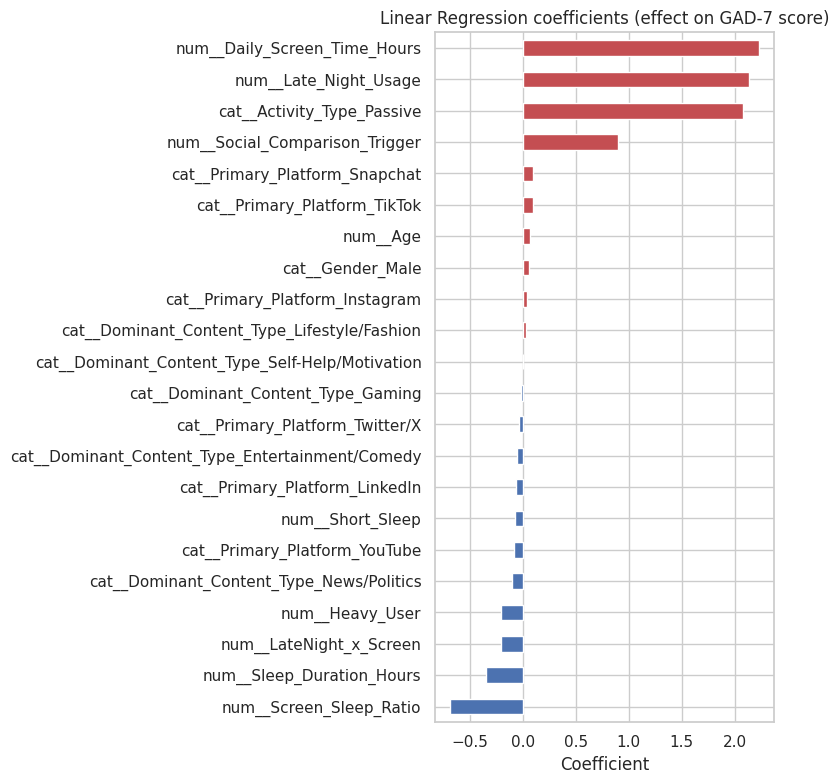

In [20]:
# Which predictors drive the linear model? (standardized numeric coefficients are comparable)
lin = fitted["Linear Regression"]
names = lin.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lin.named_steps["model"].coef_, index=names).sort_values()
plt.figure(figsize=(8, 8))
coefs.plot.barh(color=["#C44E52" if v > 0 else "#4C72B0" for v in coefs])
plt.title("Linear Regression coefficients (effect on GAD-7 score)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

### 5.4 Model 2: Random Forest

I tune `max_depth` and `min_samples_leaf` with 5-fold cross-validation on the **training set only**, then evaluate the best model once on the test set.

In [21]:
param_grid = {
    "model__max_depth": [4, 6, 8, None],
    "model__min_samples_leaf": [5, 10, 20],
}
rf_search = GridSearchCV(
    build_pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    param_grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print("Best parameters:", rf_search.best_params_)
print("Best CV RMSE:", round(-rf_search.best_score_, 3))

Best parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 20}
Best CV RMSE: 2.883


In [22]:
best_rf = rf_search.best_estimator_
evaluate("Random Forest (tuned)", best_rf)
pd.DataFrame(results)

,Model,CV R2 (train),Test RMSE,Test MAE,Test R2
0,Mean baseline,-0.001,4.552,3.783,-0.001
1,Linear Regression,0.618,2.826,2.295,0.614
2,Random Forest (tuned),0.616,2.835,2.305,0.612


## 6. Evaluation and comparison

In [23]:
results_df = pd.DataFrame(results).set_index("Model")
results_df

,CV R2 (train),Test RMSE,Test MAE,Test R2
Model,,,,
Mean baseline,-0.001,4.552,3.783,-0.001
Linear Regression,0.618,2.826,2.295,0.614
Random Forest (tuned),0.616,2.835,2.305,0.612


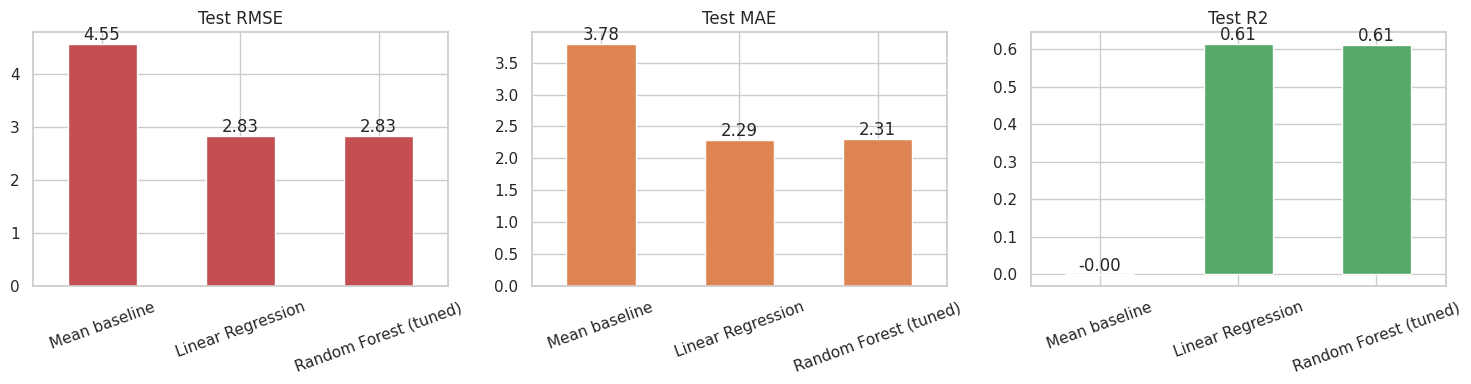

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, color in zip(axes, ["Test RMSE", "Test MAE", "Test R2"], ["#C44E52", "#DD8452", "#55A868"]):
    results_df[metric].plot.bar(ax=ax, color=color)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(results_df[metric]):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

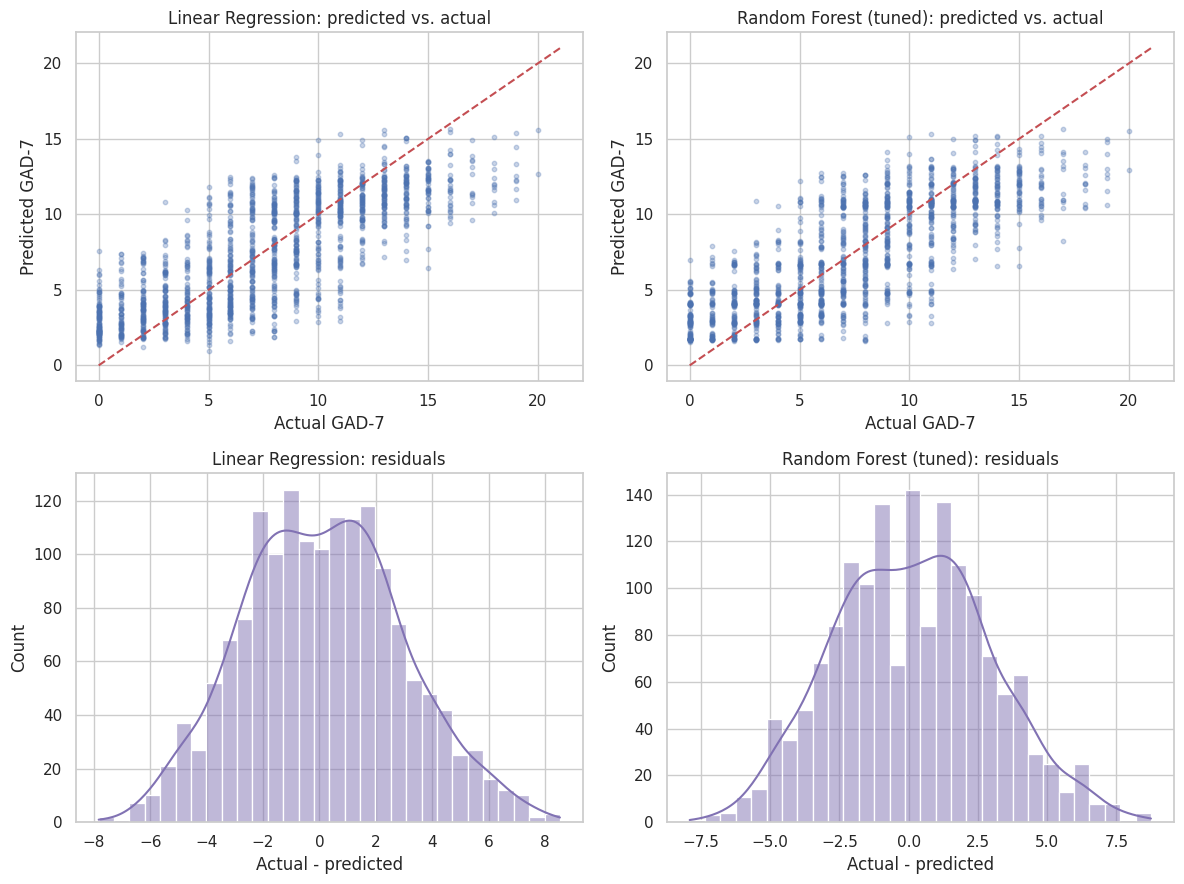

In [25]:
# Predicted vs. actual and residuals for the two real models
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for col, name in enumerate(["Linear Regression", "Random Forest (tuned)"]):
    pred = fitted[name].predict(X_test)
    axes[0, col].scatter(y_test, pred, alpha=0.3, s=10)
    axes[0, col].plot([0, 21], [0, 21], "r--")
    axes[0, col].set_title(f"{name}: predicted vs. actual")
    axes[0, col].set_xlabel("Actual GAD-7")
    axes[0, col].set_ylabel("Predicted GAD-7")
    sns.histplot(y_test - pred, bins=30, kde=True, ax=axes[1, col], color="#8172B3")
    axes[1, col].set_title(f"{name}: residuals")
    axes[1, col].set_xlabel("Actual - predicted")
plt.tight_layout()
plt.show()

### 6.1 Which features matter? (permutation importance on the test set)

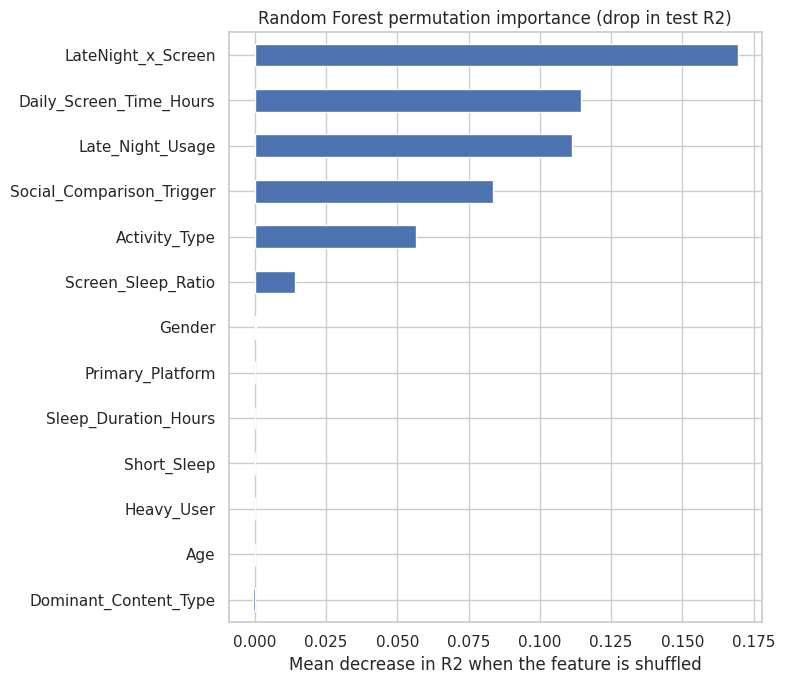

LateNight_x_Screen           0.169
Daily_Screen_Time_Hours      0.115
Late_Night_Usage             0.111
Social_Comparison_Trigger    0.084
Activity_Type                0.057
Screen_Sleep_Ratio           0.014
Gender                       0.000
Primary_Platform             0.000
dtype: float64

In [26]:
perm = permutation_importance(fitted["Random Forest (tuned)"], X_test, y_test,
                              n_repeats=10, random_state=RANDOM_STATE, scoring="r2")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(8, 7))
imp.plot.barh(color="#4C72B0")
plt.title("Random Forest permutation importance (drop in test R2)")
plt.xlabel("Mean decrease in R2 when the feature is shuffled")
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).round(3).head(8)

### 6.2 Do content-related variables add anything beyond screen time and sleep?

This answers the second half of the research question. I refit both models using (a) only usage, sleep and demographic variables, and (b) the same set plus the content proxies (`Activity_Type`, `Dominant_Content_Type`, `Primary_Platform`, `Social_Comparison_Trigger`). Random Forest settings are the tuned ones from above.

In [27]:
usage_num = ["Age", "Daily_Screen_Time_Hours", "Sleep_Duration_Hours", "Late_Night_Usage",
             "Screen_Sleep_Ratio", "Heavy_User", "Short_Sleep", "LateNight_x_Screen"]
content_cat = ["Activity_Type", "Dominant_Content_Type", "Primary_Platform"]
rf_params = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}

feature_sets = {
    "Usage + sleep only": (["Gender"], usage_num),
    "+ content proxies": (["Gender"] + content_cat, usage_num + ["Social_Comparison_Trigger"]),
}
rows = []
for set_name, (cats, nums) in feature_sets.items():
    for model_name, model in [("Linear Regression", LinearRegression()),
                              ("Random Forest", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1, **rf_params))]:
        p = build_pipeline(model, cats, nums).fit(X_train, y_train)
        pred = p.predict(X_test)
        rows.append({"Feature set": set_name, "Model": model_name,
                     "Test RMSE": round(mean_squared_error(y_test, pred) ** 0.5, 3),
                     "Test R2": round(r2_score(y_test, pred), 3)})
ablation = pd.DataFrame(rows)
ablation

,Feature set,Model,Test RMSE,Test R2
0,Usage + sleep only,Linear Regression,3.020,0.559
1,Usage + sleep only,Random Forest,3.034,0.555
2,+ content proxies,Linear Regression,2.826,0.614
3,+ content proxies,Random Forest,2.835,0.612


In [28]:
ablation.pivot(index="Model", columns="Feature set", values="Test R2").assign(
    gain=lambda d: (d["+ content proxies"] - d["Usage + sleep only"]).round(3))

Feature set,+ content proxies,Usage + sleep only,gain
Model,,,
Linear Regression,0.614,0.559,0.055
Random Forest,0.612,0.555,0.057


## 7. Findings and what I would change with more time

On unseen users, both models explained about 61% of the variance in GAD-7 anxiety (test R² of 0.614 for Linear Regression and 0.612 for the tuned Random Forest, with an RMSE of about 2.8 points compared with 4.55 for a mean-only baseline), so screen time, late-night use, sleep and content habits are strongly associated with anxiety in this dataset. The Random Forest did not beat the simple Linear Regression, which suggests the relationships here are mostly additive and linear rather than hidden in complex interactions. Heavy use late at night was the strongest signal, with total screen time, late-night use, social-comparison triggers and passive scrolling ranking next. Adding the content proxies raised R² from about 0.56 to 0.61 for both models, so how people use social media explains something that hours online and sleep do not, although time-of-day and duration still matter most. These results are correlational, based on self-reports from 18 to 22 year olds, and the data is so clean that it may be synthetic, so I cannot claim that content causes anxiety and real-world accuracy would probably be lower. With more time I would repeat the analysis for the PHQ-9 depression score, try classification into severity bands evaluated with F1, test gradient boosting, and validate on a real, messier dataset that measures content quality more directly.